# Whole-region segmentation benchmark (§5.1)

Level 1 of the evaluation hierarchy: did each method recover the individual cells and their boundaries? Every
method is scored against the expert annotations on the six regions of the held-out test slide (Slide 2, SLIDE-0236), whole — one ground-truth
map per region, expert-flagged (*wrong*) nuclei ignored — with the matching `mxseg eval` uses: instance F1, average
precision at IoU 0.5 and averaged over 0.5–0.9, panoptic quality, precision, recall and count calibration. Every test
region is expert-reviewed, so model errors are not confounded by annotation errors; trained methods are pooled over
their seeds (mean ± std) and the figures draw one seed. Then what *kind* of errors each method makes (the DeepCell
taxonomy of Greenwald et al. 2022), and the qualitative crops. Notebook 07 carries the fuller inference report. The second held-out slide (Slide 3, SLIDE-0233, four immune-rich fields) gets its own table
right after the main one, re-aggregated from the stored per-region results; the two slides are never pooled. Trained rows: ViT-B/16
encoders, 10-epoch budget, three seeds.

Needs the stored test-region predictions of each method (`mxseg eval -b configs/baselines/<method>.yaml --split test
--unit region --store-predictions`). Writes `outputs/analysis/benchmark_region.csv` and `taxonomy_<method>.csv`, which
notebooks 03–05 read.

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from mxdata import DEFAULT_DATASET, load_config, load_regions, ingest, apply_qc_policy
from mxdata.data import LiveSource
from mxseg.evaluate import split_regions_of, read_prediction

# ---- edit here ---------------------------------------------------------------------------------------------------------
METHODS_ALL = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "kodiakb_frozen", "dinov3b_frozen", "cellpose_ft",
               "cellpose", "cpdino", "instanseg", "sam3", "sam3_text", "sam2"]
SHOW_METHODS = ["cellpose", "cellpose_ft", "sam3", "dinov3b_frozen", "unet_flows", "kodiakb_flows"]
SEED = 0                                        # the seed drawn in every figure; every table pools the seeds (mean ± std)
TEST_SLIDE = "SLIDE-0236"                       # the paper's Slide 2: every §5 analysis runs on it; the other held-out slide (SLIDE-0233,
                                                # Slide 3) is scored in notebook 02's Slide-3 table from the stored per-region results
# METHODS_ALL: the paper's order (ViT-B rows, 10-epoch budget, 3 seeds); a method enters once its test-slide predictions exist.
# SHOW_METHODS: the image figures.
# ------------------------------------------------------------------------------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ANALYSIS = REPO / "outputs" / "analysis"
ANALYSIS.mkdir(parents=True, exist_ok=True)
PRED = REPO / "outputs" / "region" / "test"        # mxseg eval -b configs/baselines/<method>.yaml --split test --unit region --store-predictions
cfg = load_config(REPO / "configs" / "dataset.yaml")

LABEL = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B/16", "dinov3b_flows": "DINOv3 B/16", "kodiakb_frozen": "KODIAK B/16, frozen",
         "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted", "cellpose": "Cellpose-SAM, zero-shot",
         "cpdino": "Cellpose (DINOv3), zero-shot", "instanseg": "InstanSeg", "sam3": "SAM 3, exemplar", "sam3_text": "SAM 3, text",
         "sam2": "SAM 2.1, prototype",
         "kodiak_flows": "KODIAK S/16", "dinov3_flows": "DINOv3 S/16", "dinov3_frozen": "DINOv3 S/16, frozen", "kodiak_frozen": "KODIAK S/16, frozen"}
SHORT = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B", "dinov3b_flows": "DINOv3 B", "kodiakb_frozen": "KODIAK B frozen",
         "dinov3b_frozen": "DINOv3 B frozen", "cellpose_ft": "Cellpose adapted", "cellpose": "Cellpose-SAM 0-shot", "cpdino": "Cellpose-DINO 0-shot",
         "instanseg": "InstanSeg", "sam3": "SAM 3 exemplar", "sam3_text": "SAM 3 text", "sam2": "SAM 2.1",
         "kodiak_flows": "KODIAK S", "dinov3_flows": "DINOv3 S", "dinov3_frozen": "DINOv3 S frozen", "kodiak_frozen": "KODIAK S frozen"}
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E", "dinov3b_frozen": "#D3BF8C",
          "cellpose_ft": "#EB6834", "cellpose": "#8A8A8A", "cpdino": "#5A5A5A", "instanseg": "#3C9D9B",
          "sam3": "#1BAF7A", "sam3_text": "#E87BA4", "sam2": "#9A86E0",
          "kodiak_flows": "#C43E4E", "dinov3_flows": "#B08A2E", "dinov3_frozen": "#D3BF8C", "kodiak_frozen": "#DF959E"}   # the paper's swatches; frozen = tints
INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PHENO_COLOR = {"Epithelial": "#2A78D6", "Immune": "#C43E4E", "Other": "#AEB2B8"}
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    """Nature-style bold panel letter, outside the axes' top-left corner."""
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    """A short label inside an image panel (region, method) — never a sentence."""
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def barh_clean(ax):
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

def hex2rgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def short(key):
    return key.split("_")[-1]

def norm01(img, lo=1, hi=99):
    a, b = np.percentile(img, (lo, hi))
    return np.clip((img - a) / max(b - a, 1e-6), 0, 1)

per_slide = split_regions_of(DEFAULT_DATASET, "test", cfg.slides)          # the protocol: held-out test slides, every region reviewed
assert TEST_SLIDE in per_slide, f"{TEST_SLIDE} is not a test slide of the split: {list(per_slide)}"
OTHER_TEST = [s for s in per_slide if s != TEST_SLIDE]                     # also held out (Slide 3): never pooled with TEST_SLIDE here
paths, mx, _ = ingest(TEST_SLIDE, None)
ids = sorted(per_slide[TEST_SLIDE])
regions = {r.region_id: r for r in load_regions(paths, ids, cfg.min_area_px)}
src = LiveSource(mx, list(regions.values()), cfg.markers, cfg.level)
TEST = {}                                          # key -> DAPI, labels (expert-flagged nuclei zeroed) and their ignore mask
for key in src.keys:
    rs = src.load(key)
    labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
    r = regions[int(key.split("_R")[-1])]
    TEST[key] = dict(dapi=rs.image[0], labels=labels, ignore=ignore, region=r, has_qc=bool(r.has_qc))
PX_UM = float(mx.pixel_size_um or 0.325)

def runs_of(m):
    """The stored, complete runs of a method (every test region predicted): <method>_s<seed> for trained rows, the bare name for zero-shot rows."""
    names = sorted(d.name for d in PRED.glob(f"{m}_s[0-9]*") if d.is_dir()) or ([m] if (PRED / m).is_dir() else [])
    return [r for r in names if all((PRED / r / f"{k}.npz").is_file() for k in TEST)]
RUNS = {m: runs_of(m) for m in METHODS_ALL if runs_of(m)}
METHODS = list(RUNS)
RUN = {m: next((r for r in RUNS[m] if r.endswith(f"_s{SEED}")), RUNS[m][0]) for m in METHODS}   # the run drawn in the figures
if not METHODS:
    raise FileNotFoundError(f"no complete test-slide predictions under {PRED.relative_to(REPO)} — scripts/finetune_all.sh evaluates every run:  "
                            "mxseg eval -b configs/baselines/<method>.yaml --split test --unit region")
if len(METHODS) < len(METHODS_ALL):
    print("not evaluated yet, skipped:", ", ".join(LABEL[m] for m in METHODS_ALL if m not in METHODS))
SHOW = [m for m in SHOW_METHODS if m in METHODS]

def pred_of(run, key):
    """A stored instance map: ``run`` is a run name (<method>_s<seed>, or the bare name of a zero-shot row) or a method (its drawn run)."""
    return read_prediction(PRED / RUN.get(run, run) / f"{key}.npz")

def tag(key):
    return short(key) + ("*" if TEST[key]["has_qc"] else "")

def scalebar(ax, npx, um=50, color="white"):
    L = um / PX_UM
    x1, y = npx * 0.96, npx * 0.94
    ax.plot([x1 - L, x1], [y, y], color=color, lw=2.2, solid_capstyle="butt")
    ax.text(x1 - L / 2, y - npx * 0.025, f"{um} µm", color=color, ha="center", va="bottom", fontsize=7)

print(f"test slide {TEST_SLIDE}: {len(TEST)} regions ({', '.join(tag(k) for k in TEST)}; * = reviewed) | methods (seeds): "
      + ", ".join(f"{LABEL[m]} ({len(RUNS[m])})" for m in METHODS) + f" | figures draw seed {SEED}"
      + (f" | also held out, analysed separately: {', '.join(OTHER_TEST)}" if OTHER_TEST else ""))

/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


test slide SLIDE-0236: 6 regions (R01*, R02*, R03*, R04*, R05*, R06*; * = reviewed) | methods (seeds): U-Net (3), KODIAK B/16 (3), DINOv3 B/16 (3), KODIAK B/16, frozen (3), DINOv3 B/16, frozen (3), Cellpose, adapted (3), Cellpose-SAM, zero-shot (1), Cellpose (DINOv3), zero-shot (1), InstanSeg (1), SAM 3, exemplar (1), SAM 3, text (1), SAM 2.1, prototype (1) | figures draw seed 0 | also held out, analysed separately: SLIDE-0233


## 1. The benchmark table

In [2]:
from mxseg.metrics import IOU_THRESHOLDS, aggregate, score_patch

rows = []
for m in METHODS:
    for run in RUNS[m]:
        for key, T in TEST.items():
            rows.append({"method": m, "run": run, "key": key, "has_qc": T["has_qc"], **score_patch(T["labels"], pred_of(run, key), ignore=T["ignore"])})
per_region = pd.DataFrame(rows)
KEYS = ["f1@0.5", "ap@0.5", "ap@0.5:0.9", "pq@0.5", "precision@0.5", "recall@0.5", "count_ratio"]
bench_runs = []
for (m, run), pr in per_region.groupby(["method", "run"], sort=False):
    a_all = aggregate(pr.to_dict("records"))
    bench_runs.append({"method": m, "run": run, **{k: a_all[k] for k in KEYS}, **{f"f1@{t:g}": a_all[f"f1@{t:g}"] for t in IOU_THRESHOLDS}, "n_gt": a_all["n_gt"]})
bench_runs = pd.DataFrame(bench_runs)
num = [c for c in bench_runs.columns if c not in ("method", "run")]
bench = bench_runs.groupby("method", sort=False)[num].mean().loc[METHODS]           # mean over seeds: the paper's numbers
bench_sd = bench_runs.groupby("method", sort=False)[num].std(ddof=0).loc[METHODS]
bench["seeds"] = bench_runs.groupby("method").run.count().loc[METHODS]
bench.to_csv(ANALYSIS / "benchmark_region.csv"); bench_sd.add_suffix("_sd").to_csv(ANALYSIS / "benchmark_region_sd.csv")
bench_runs.to_csv(ANALYSIS / "benchmark_runs.csv", index=False); per_region.to_csv(ANALYSIS / "benchmark_per_region.csv", index=False)

def pm(m, k):
    return f"{bench.loc[m, k]:.3f} ± {bench_sd.loc[m, k]:.3f}" if bench.loc[m, "seeds"] > 1 else f"{bench.loc[m, k]:.3f}"
table = pd.DataFrame({k: [pm(m, k) for m in METHODS] for k in KEYS}, index=[LABEL[m] for m in METHODS])
table.columns = ["F1", "AP", "AP.5:.9", "PQ", "Prec.", "Rec.", "Count"]
table.insert(0, "seeds", bench.seeds.values)
print(f"{int(bench.n_gt.iloc[0])} scored cells on the {len(TEST)} reviewed regions of {TEST_SLIDE} | mean ± std over seeds")
display(table)

6152 scored cells on the 6 reviewed regions of SLIDE-0236 | mean ± std over seeds


,seeds,F1,AP,AP.5:.9,PQ,Prec.,Rec.,Count
U-Net,3,0.875 ± 0.003,0.778 ± 0.005,0.480 ± 0.005,0.685 ± 0.004,0.915 ± 0.004,0.838 ± 0.003,0.915 ± 0.003
KODIAK B/16,3,0.877 ± 0.008,0.781 ± 0.012,0.504 ± 0.009,0.697 ± 0.007,0.929 ± 0.000,0.830 ± 0.014,0.894 ± 0.015
DINOv3 B/16,3,0.863 ± 0.010,0.759 ± 0.015,0.451 ± 0.017,0.665 ± 0.011,0.924 ± 0.004,0.809 ± 0.014,0.875 ± 0.011
"KODIAK B/16, frozen",3,0.814 ± 0.008,0.686 ± 0.011,0.392 ± 0.007,0.618 ± 0.006,0.910 ± 0.007,0.736 ± 0.008,0.809 ± 0.003
"DINOv3 B/16, frozen",3,0.840 ± 0.002,0.724 ± 0.003,0.424 ± 0.009,0.644 ± 0.005,0.919 ± 0.003,0.773 ± 0.004,0.841 ± 0.007
"Cellpose, adapted",3,0.901 ± 0.005,0.819 ± 0.008,0.551 ± 0.011,0.726 ± 0.007,0.923 ± 0.005,0.879 ± 0.008,0.952 ± 0.010
"Cellpose-SAM, zero-shot",1,0.781,0.641,0.292,0.550,0.701,0.883,1.261
"Cellpose (DINOv3), zero-shot",1,0.781,0.641,0.276,0.541,0.717,0.858,1.197
InstanSeg,1,0.766,0.620,0.313,0.556,0.856,0.693,0.809
"SAM 3, exemplar",1,0.842,0.727,0.403,0.633,0.857,0.828,0.966


### Slide 3, the second held-out slide

The four immune-rich fields of SLIDE-0233 are held out exactly like Slide 2 and scored by the same `mxseg eval` call; the table below re-aggregates its stored per-region counts for those fields alone (mean ± std over seeds). Nothing in this chain pools the two slides.


In [3]:
# Slide 3 (SLIDE-0233): from the per-region tables mxseg eval stored for every run, restricted to that slide's fields
RESULTS = REPO / "results" / "region" / "test"
for other in OTHER_TEST:
    rows3 = []
    for m in METHODS:
        for run in RUNS[m]:
            f = RESULTS / run / "per_region.csv"
            if not f.is_file():
                continue
            pr = pd.read_csv(f); pr = pr[pr.key.str.startswith(other + "_")]
            if len(pr):
                a = aggregate(pr.to_dict("records")); rows3.append({"method": m, "run": run, "n_regions": len(pr), **{k: a[k] for k in KEYS}, "n_gt": a["n_gt"]})
    if not rows3:
        print(f"{other}: no stored per-region results"); continue
    b3 = pd.DataFrame(rows3); num3 = [c for c in b3.columns if c not in ("method", "run")]
    b3m = b3.groupby("method", sort=False)[num3].mean().reindex([m for m in METHODS if m in set(b3.method)])
    b3s = b3.groupby("method", sort=False)[num3].std(ddof=0).reindex(b3m.index); b3m["seeds"] = b3.groupby("method").run.count().reindex(b3m.index)
    b3m.to_csv(ANALYSIS / f"benchmark_region_{other}.csv"); b3s.add_suffix("_sd").to_csv(ANALYSIS / f"benchmark_region_{other}_sd.csv")
    t3 = pd.DataFrame({k: [f"{b3m.loc[m, k]:.3f} ± {b3s.loc[m, k]:.3f}" if b3m.loc[m, "seeds"] > 1 else f"{b3m.loc[m, k]:.3f}" for m in b3m.index] for k in KEYS},
                      index=[LABEL[m] for m in b3m.index])
    t3.columns = ["F1", "AP", "AP.5:.9", "PQ", "Prec.", "Rec.", "Count"]; t3.insert(0, "seeds", b3m.seeds.values)
    print(f"{other}: {int(b3m.n_gt.iloc[0])} scored cells on {int(b3m.n_regions.iloc[0])} reviewed fields | mean ± std over seeds")
    display(t3)


SLIDE-0233: 2329 scored cells on 4 reviewed fields | mean ± std over seeds


,seeds,F1,AP,AP.5:.9,PQ,Prec.,Rec.,Count
U-Net,3,0.786 ± 0.002,0.647 ± 0.003,0.397 ± 0.008,0.612 ± 0.005,0.861 ± 0.003,0.723 ± 0.003,0.840 ± 0.005
KODIAK B/16,3,0.784 ± 0.007,0.645 ± 0.010,0.422 ± 0.009,0.623 ± 0.007,0.872 ± 0.002,0.712 ± 0.012,0.816 ± 0.013
DINOv3 B/16,3,0.765 ± 0.010,0.620 ± 0.013,0.372 ± 0.009,0.589 ± 0.008,0.863 ± 0.003,0.688 ± 0.016,0.797 ± 0.019
"KODIAK B/16, frozen",3,0.726 ± 0.009,0.570 ± 0.011,0.328 ± 0.005,0.551 ± 0.006,0.850 ± 0.008,0.633 ± 0.009,0.745 ± 0.005
"DINOv3 B/16, frozen",3,0.754 ± 0.002,0.605 ± 0.003,0.353 ± 0.009,0.575 ± 0.004,0.868 ± 0.005,0.667 ± 0.001,0.768 ± 0.004
"Cellpose, adapted",3,0.797 ± 0.003,0.662 ± 0.004,0.445 ± 0.008,0.640 ± 0.005,0.859 ± 0.005,0.743 ± 0.007,0.864 ± 0.012
"Cellpose-SAM, zero-shot",1,0.655,0.486,0.234,0.465,0.586,0.741,1.263
"Cellpose (DINOv3), zero-shot",1,0.662,0.494,0.230,0.465,0.604,0.732,1.213
InstanSeg,1,0.657,0.489,0.266,0.486,0.767,0.574,0.748
"SAM 3, exemplar",1,0.734,0.580,0.324,0.550,0.810,0.672,0.830


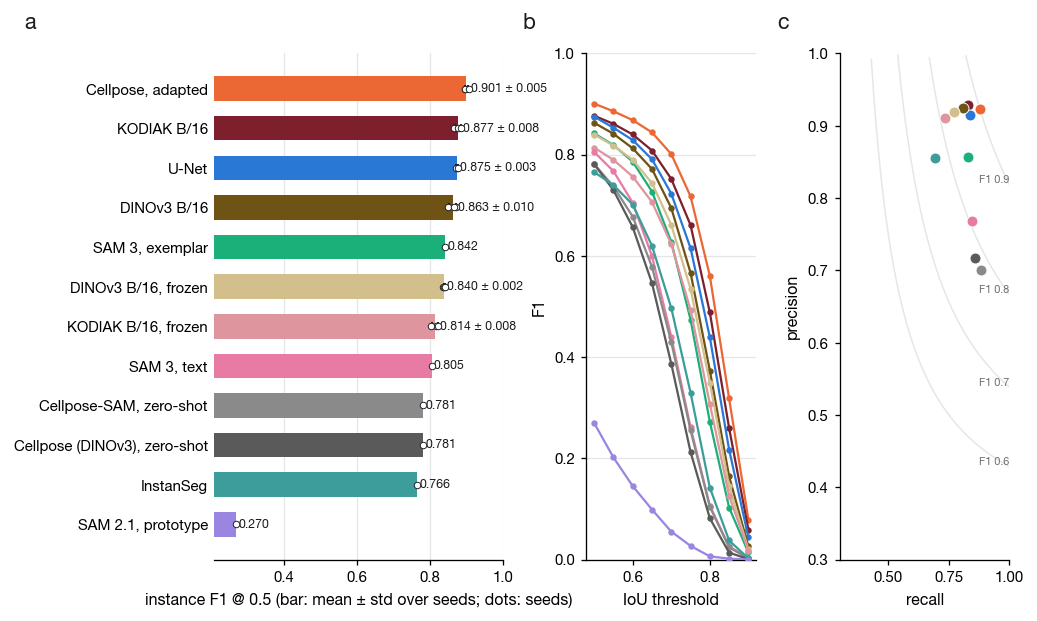

In [4]:
order = list(bench.sort_values("f1@0.5", ascending=False).index)
y = np.arange(len(order))[::-1]
thr = list(IOU_THRESHOLDS)
fig = plt.figure(figsize=(7.6, 0.55 + 0.26 * len(order) + 1.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.7, 1, 1], wspace=0.4)
a = fig.add_subplot(gs[0])                                                     # a - F1 per method: mean ± std over seeds, seeds as dots
for i, m in enumerate(order):
    sd = bench_sd.loc[m, "f1@0.5"] if bench.loc[m, "seeds"] > 1 else 0
    a.barh(y[i], bench.loc[m, "f1@0.5"], color=MCOLOR[m], height=0.62, zorder=3, xerr=sd or None, error_kw=dict(lw=0.8, capsize=2, ecolor=INK))
    runs_m = bench_runs[bench_runs.method == m]
    a.scatter(runs_m["f1@0.5"], [y[i]] * len(runs_m), s=12, color="white", edgecolor=INK, lw=0.5, zorder=4)
    a.text(max(runs_m["f1@0.5"].max(), bench.loc[m, "f1@0.5"] + sd) + 0.006, y[i], pm(m, "f1@0.5"), va="center", fontsize=6.6, color=INK)
a.set_yticks(y, [LABEL[m] for m in order])
a.set_xlim(max(0, bench_runs["f1@0.5"].min() - 0.06), min(1.0, bench_runs["f1@0.5"].max() + 0.12))
a.set_xlabel("instance F1 @ 0.5 (bar: mean ± std over seeds; dots: seeds)")
xgrid(a); barh_clean(a)
panel(a, "a", dx=-0.62)
b = fig.add_subplot(gs[1])                                                     # b - F1 vs IoU threshold
for m in order:
    b.plot(thr, [bench.loc[m, f"f1@{t:g}"] for t in thr], color=MCOLOR[m], marker="o", ms=2.4, lw=1.2, zorder=3)
b.set_xlabel("IoU threshold"); b.set_ylabel("F1"); b.set_ylim(0, 1); ygrid(b)
panel(b, "b", dx=-0.3)
c = fig.add_subplot(gs[2])                                                     # c - precision vs recall
rr = np.linspace(0.3, 1, 200)
for f in (0.6, 0.7, 0.8, 0.9):
    p = f * rr / np.maximum(2 * rr - f, 1e-6)
    ok = (p <= 1) & (p >= 0.3)
    c.plot(rr[ok], p[ok], color=GRID, lw=0.8, zorder=1)
    c.text(rr[ok][-1], p[ok][-1], f"F1 {f}", fontsize=5.8, color=MUTED, ha="right", va="bottom")
for m in order:
    c.scatter(bench.loc[m, "recall@0.5"], bench.loc[m, "precision@0.5"], color=MCOLOR[m], s=34, zorder=3, edgecolor="white", lw=0.5)
c.set_xlabel("recall"); c.set_ylabel("precision"); c.set_xlim(0.3, 1); c.set_ylim(0.3, 1)
panel(c, "c", dx=-0.3)
plt.show()

**Figure 1 — The benchmark, drawn.** (a) Instance F1 (IoU ≥ 0.5) of every method on the six reviewed regions of the
test slide, mean ± std over seeds with the seeds as dots: two methods whose bars overlap within their error are not
different. (b) F1 as the overlap threshold tightens from 0.5 to 0.9:
the slope is boundary agreement, not detection. (c) Precision against recall at IoU 0.5 with iso-F1 curves; count
calibration is the position along the anti-diagonal (below it a method finds too many objects).

## 2. Error taxonomy

F1 counts errors; the downstream levels care *which way* a cell was wrong. Every scored nucleus is classified with the
DeepCell framework (Greenwald et al. 2022): a bipartite overlap graph at IoU ≥ 0.1, one-to-one matches at IoU ≥ 0.6 are
**correct**, and each remaining component is a **split** (one nucleus, ≥ 2 predictions), a **merge** (one prediction,
≥ 2 nuclei), a **catastrophe** (both entangled) or **missed**; **gained** instances are the prediction-side false
positives, excluding predictions that lie mostly on expert-flagged nuclei.

                              correct  split  merge  catastrophe  missed  gained
method                                                                          
U-Net                            79.4    0.6    5.7          0.3    14.1   249.3
KODIAK B/16                      79.5    0.5    4.7          0.2    15.1   204.0
DINOv3 B/16                      76.2    0.3    5.9          0.3    17.3   204.3
KODIAK B/16, frozen              68.4    0.3    6.3          0.2    24.8   216.0
DINOv3 B/16, frozen              72.7    0.3    5.7          0.2    21.1   205.3
Cellpose, adapted                84.7    0.7    3.4          0.1    11.1   272.7
Cellpose-SAM, zero-shot          76.6    6.9    2.0          1.1    13.4  1331.0
Cellpose (DINOv3), zero-shot     72.2    5.1    1.9          1.0    19.9  1119.0
InstanSeg                        63.4    1.1    1.8          0.2    33.4   427.0
SAM 3, exemplar                  77.3    1.6    3.9          0.6    16.7   516.0
SAM 3, text                 

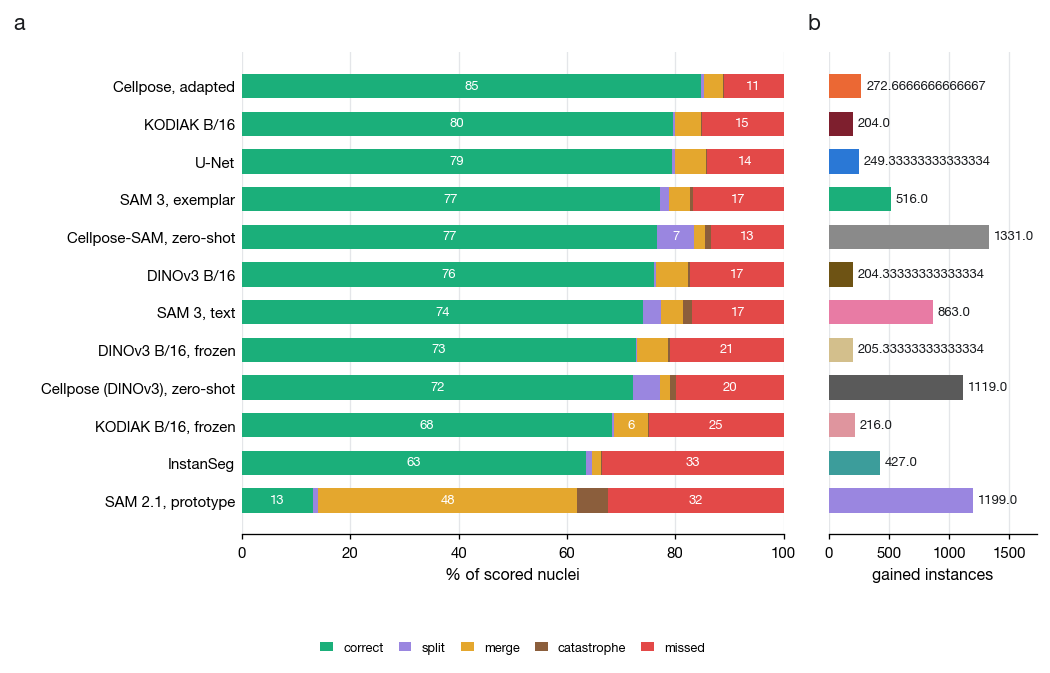

In [5]:
from mxseg.analysis import TAXONOMY, classify_errors

CLS_COLOR = {"correct": "#1BAF7A", "split": "#9A86E0", "merge": "#E4A72E", "catastrophe": "#8B5E3C", "missed": "#E34948"}
GAIN_COLOR = "#5C7CFA"
tax, gained, fate_runs = {}, {}, []
for m in METHODS:
    for run in RUNS[m]:
        frames = []
        for key, T in TEST.items():
            df, g = classify_errors(T["labels"], pred_of(run, key), T["ignore"])
            df["region"], df["method"], df["run"] = key, m, run
            frames.append(df)
            gained[(run, key)] = g
        t = pd.concat(frames, ignore_index=True)
        t.to_csv(ANALYSIS / f"taxonomy_{run}.csv", index=False)                   # one table per run: notebook 03 reads every seed
        fate_runs.append({"method": m, "run": run, **{c: 100 * (t.cls == c).mean() for c in TAXONOMY}, "gained": sum(len(gained[(run, k)]) for k in TEST)})
        if run == RUN[m]:                                                      # the drawn seed, also under the method's name (notebook 05)
            tax[m] = t
            t.to_csv(ANALYSIS / f"taxonomy_{m}.csv", index=False)
            for k in TEST:
                gained[(m, k)] = gained[(run, k)]
fate_runs = pd.DataFrame(fate_runs)
fate = fate_runs.groupby("method", sort=False)[list(TAXONOMY) + ["gained"]].mean().loc[METHODS]   # mean over seeds
fate.to_csv(ANALYSIS / "taxonomy_summary.csv")
print(fate.round(1).rename(index=LABEL).to_string())

order = list(fate.sort_values("correct", ascending=False).index)
y = np.arange(len(order))[::-1]
fig = plt.figure(figsize=(7.6, 0.5 + 0.27 * len(order) + 0.9))
gs = fig.add_gridspec(1, 2, width_ratios=[2.6, 1], wspace=0.12)
a = fig.add_subplot(gs[0])                                                     # a - nucleus fate
left = np.zeros(len(order))
for cls in TAXONOMY:
    vals = fate.loc[order, cls].values
    a.barh(y, vals, left=left, color=CLS_COLOR[cls], height=0.64, zorder=3, label=cls)
    for i, v in enumerate(vals):
        if v >= 6:
            a.text(left[i] + v / 2, y[i], f"{v:.0f}", ha="center", va="center", fontsize=7, color="white", fontweight="bold", zorder=4)
    left += vals
a.set_yticks(y, [LABEL[m] for m in order]); a.set_xlim(0, 100); a.set_xlabel("% of scored nuclei")
a.legend(ncol=5, fontsize=6.8, loc="upper center", bbox_to_anchor=(0.5, -0.2), handlelength=1.0, columnspacing=1.2)
xgrid(a); barh_clean(a)
panel(a, "a", dx=-0.4)
b = fig.add_subplot(gs[1])                                                     # b - gained instances
fp = fate.loc[order, "gained"].values
b.barh(y, fp, color=[MCOLOR[m] for m in order], height=0.64, zorder=3)
for i, v in enumerate(fp):
    b.text(v + max(fp) * 0.03, y[i], f"{v}", va="center", fontsize=7, color=INK)
b.set_yticks([]); b.set_xlim(0, max(fp) * 1.3); b.set_xlabel("gained instances")
xgrid(b); barh_clean(b)
panel(b, "b", dx=-0.04)
plt.show()

**Figure 2 — What kind of error.** (a) The fate of every scored expert nucleus under each method, as the share of the
five DeepCell classes (numbers: percent); methods sorted by their *correct* share. (b) Gained instances — false positives
the left panel cannot show. Methods fail in different directions: a fragmenting method has splits and many gained
instances and almost no merges; a conservative one trades those for missed dim, thin nuclei. Merges are the class
that mixes phenotypes (notebook 03); missed cells are the ones that lose their relationships (notebook 04).

## 3. Qualitative comparison

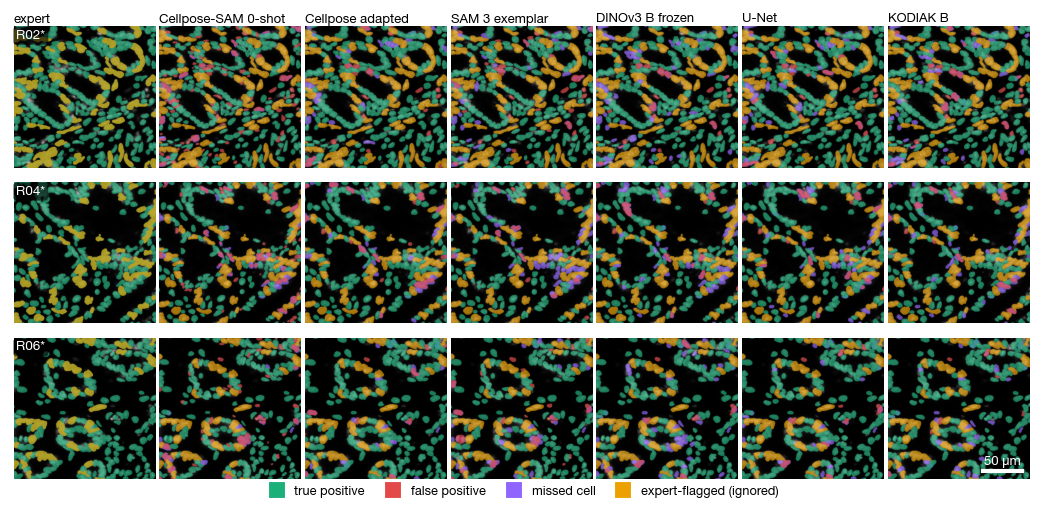

In [6]:
from mxseg.metrics import instance_outcomes

VERDICT = {"tp": "#1BAF7A", "fp": "#E34948", "fn": "#9064FF", "wrong": "#EDA100"}                # the paper's verdict colors
CROPS = {f"{TEST_SLIDE}_R02": (200, 300), f"{TEST_SLIDE}_R04": (500, 900), f"{TEST_SLIDE}_R06": (300, 100)}   # (y, x) of the 512² crops
CROP = 512
CROPS = {k: v for k, v in CROPS.items() if k in TEST}
cols = ["expert"] + SHOW
fig, axes = plt.subplots(len(CROPS), len(cols), figsize=(7.6, 7.6 / len(cols) * len(CROPS) + 0.5), squeeze=False)
fig.subplots_adjust(left=0.005, right=0.995, top=0.96, bottom=0.05, wspace=0.03, hspace=0.04)
for r, (key, (y0, x0)) in enumerate(CROPS.items()):
    T = TEST[key]
    sl = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))
    base = np.repeat(norm01(T["dapi"][sl])[..., None] * 0.7, 3, -1)
    img = base.copy()                                                          # expert: scored green, flagged amber
    L, W = T["labels"][sl] > 0, T["ignore"][sl]
    img[L] = 0.35 * img[L] + 0.65 * hex2rgb(VERDICT["tp"]); img[W] = 0.35 * img[W] + 0.65 * hex2rgb(VERDICT["wrong"])
    axes[r, 0].imshow(img)
    for c, m in enumerate(SHOW, 1):
        o = instance_outcomes(T["labels"], pred_of(m, key), ignore=T["ignore"])
        lut_p = np.array([hex2rgb(VERDICT[s]) if s in VERDICT else np.zeros(3) for s in o["pred_status"]])
        has_p = np.array([s in ("tp", "fp") for s in o["pred_status"]])
        has_g = np.array([s == "fn" for s in o["gt_status"]])
        img = base.copy()
        P, Gm = o["pred"][sl], o["gt"][sl]
        mk = has_g[Gm]; img[mk] = 0.35 * img[mk] + 0.65 * hex2rgb(VERDICT["fn"])
        mk = has_p[P]; img[mk] = 0.35 * img[mk] + 0.65 * lut_p[P[mk]]
        img[W] = 0.35 * base[W] + 0.65 * hex2rgb(VERDICT["wrong"])
        axes[r, c].imshow(img)
    chip(axes[r, 0], tag(key))
for c, name in enumerate(cols):
    axes[0, c].set_title("expert" if name == "expert" else SHORT[name], fontsize=7, pad=2)
for a in axes.ravel():
    a.set_axis_off()
scalebar(axes[-1, -1], CROP)
handles = [plt.Line2D([], [], marker="s", ls="", ms=7, color=v, label=k) for k, v in
           {"true positive": VERDICT["tp"], "false positive": VERDICT["fp"], "missed cell": VERDICT["fn"], "expert-flagged (ignored)": VERDICT["wrong"]}.items()]
fig.legend(handles=handles, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.0), fontsize=6.8, handletextpad=0.4, columnspacing=1.2)
plt.show()

**Figure 3 — Qualitative comparison (the paper's Figure 2).** 512² crops (166 µm) of three reviewed regions of the
test slide — R2, the large region R4 and R6 — one method per column (the drawn seed). In the expert column, green
cells are scored and amber cells carry the expert's *wrong* flag; method panels color every instance by its verdict at
IoU 0.5. The failure modes become explicit: fragmentation of dense clusters into false positives, balanced errors
without any training, and the clean separation of the dense epithelium by the flow-decoded models at the cost of
occasional misses of dim, thin cells. Edit `SHOW_METHODS` and `CROPS` to look elsewhere.

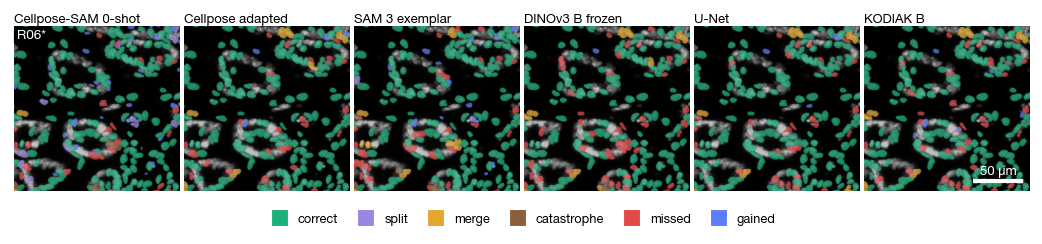

In [7]:
key, (y0, x0) = f"{TEST_SLIDE}_R06", (300, 100)                                  # the taxonomy drawn: one crop, every method
T = TEST[key]
sl = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))
base = np.repeat(norm01(T["dapi"][sl])[..., None] * 0.75, 3, -1)
n = len(SHOW)
fig, axes = plt.subplots(1, n, figsize=(7.6, 7.6 / n + 0.55), squeeze=False)
fig.subplots_adjust(left=0.005, right=0.995, top=0.93, bottom=0.06, wspace=0.03)
for a, m in zip(axes[0], SHOW):
    sub = tax[m][tax[m].region == key]
    lut = np.zeros((int(T["labels"].max()) + 1, 3)); has = np.zeros(int(T["labels"].max()) + 1, bool)
    for gid, cls in zip(sub.gt_id, sub.cls):
        lut[gid], has[gid] = hex2rgb(CLS_COLOR[cls]), True
    img = base.copy()
    L = T["labels"][sl]
    mk = has[L]; img[mk] = 0.3 * img[mk] + 0.7 * lut[L[mk]]
    P = pred_of(m, key)[sl]
    gm = np.isin(P, gained[(m, key)]); img[gm] = 0.3 * img[gm] + 0.7 * hex2rgb(GAIN_COLOR)
    a.imshow(img); a.set_axis_off()
    a.set_title(SHORT[m], fontsize=7, pad=2)
chip(axes[0, 0], tag(key))
scalebar(axes[0, -1], CROP)
handles = [plt.Line2D([], [], marker="s", ls="", ms=7, color=v, label=k) for k, v in CLS_COLOR.items()] + \
          [plt.Line2D([], [], marker="s", ls="", ms=7, color=GAIN_COLOR, label="gained")]
fig.legend(handles=handles, ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.03), fontsize=6.8, handletextpad=0.4, columnspacing=1.2)
plt.show()

**Figure 4 — The taxonomy on the tissue.** A 512² crop of region R6 of the test slide for every method, each expert
nucleus filled by its fate and gained instances in slate blue: green tissue is solved tissue, every other color is a
specific, named failure.

---
**References.** Greenwald et al., *Whole-cell segmentation of tissue images with human-level performance using
large-scale data annotation and deep learning*, Nature Biotechnology 2022 — the error taxonomy and the IoU ≥ 0.6
convention. Kirillov et al., *Panoptic Segmentation*, CVPR 2019 — PQ.